In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import harmonypy as hm

In [2]:
dta = sc.read_h5ad('../data/exam/scRNA_human_dev.h5ad')
meta = pd.read_csv('../data/exam/scRNA_human_dev.meta', index_col=0)

In [3]:
plt.rcParams.update({
    'font.family':'Arial',
    'font.size':7,
    'pdf.fonttype':42
})

In [4]:
dir_out = '../results/exam/'

# Prepare data

In [5]:
meta['version'] = meta['Sample'].str[-1].astype('category')

In [6]:
meta['version'].value_counts()

version
3    13117
2    12044
Name: count, dtype: int64

In [7]:
# add version to dta
dta.obs = dta.obs.merge(meta[['version']], left_index=True, right_index=True)

# Quality controls

In [8]:
sc.pp.calculate_qc_metrics(dta, inplace=True, log1p=True)

In [9]:
sc.pp.filter_cells(dta, min_genes=100)
sc.pp.filter_genes(dta, min_cells=3)
sc.pp.scrublet(dta, batch_key="Sample")

In [10]:
# drop doublets
counts_doublet = dta.obs['predicted_doublet'].sum()
print(f'Dropping {counts_doublet} doublets')
dta = dta[~dta.obs['predicted_doublet']].copy()

Dropping 102 doublets


# Transformation

In [11]:
# Saving count data
dta.layers["counts"] = dta.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(dta)
# Logarithmize the data
sc.pp.log1p(dta)

# Select features

In [12]:
dta.obs['Sample'] = dta.obs['Sample'].astype('category')
sc.pp.highly_variable_genes(dta, n_top_genes=10000, batch_key='Sample')

# Run PCA and UMAP

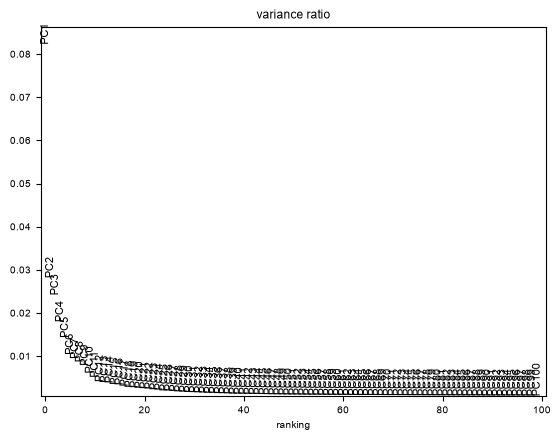

In [13]:
# inspect how many PCs to include
sc.tl.pca(dta, n_comps=100)
sc.pl.pca_variance_ratio(dta, n_pcs=100, log=False)

## check technical issues with PCs

In [17]:
help(sc.pl.pca)

Help on function pca in module scanpy.plotting._tools.scatterplots:

pca(adata: 'AnnData', *, color: 'str | Sequence[str] | None' = None, mask_obs: 'NDArray[np.bool] | str | None' = None, gene_symbols: 'str | None' = None, use_raw: 'bool | None' = None, sort_order: 'bool' = True, edges: 'bool' = False, edges_width: 'float' = 0.1, edges_color: 'str | Sequence[float] | Sequence[str]' = 'grey', neighbors_key: 'str | None' = None, arrows: 'bool' = False, arrows_kwds: 'Mapping[str, Any] | None' = None, groups: 'str | Sequence[str] | None' = None, components: 'str | Sequence[str] | None' = None, dimensions: 'tuple[int, int] | Sequence[tuple[int, int]] | None' = None, layer: 'str | None' = None, projection: "Literal['2d', '3d']" = '2d', scale_factor: 'float | None' = None, color_map: 'Colormap | str | None' = None, cmap: 'Colormap | str | None' = None, palette: 'str | Sequence[str] | Cycler | None' = None, na_color: 'ColorLike' = 'lightgray', na_in_legend: 'bool' = True, size: 'float | Sequen

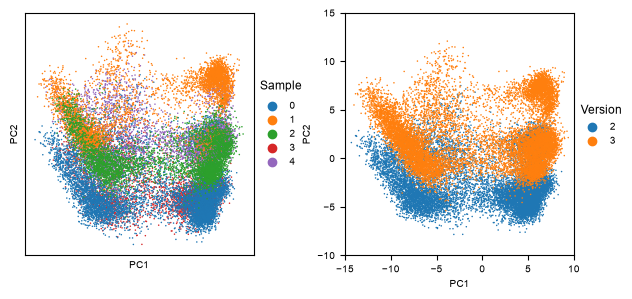

In [80]:
fig, ax = plt.subplots(1, 2, figsize=(18/2.54, 8/2.54))

sc.pl.pca(dta, color=['Sample'], dimensions=[(0, 1)],
          ax=ax[0], show=False, title='')
sc.pl.pca(dta, color=['version'], dimensions=[(0, 1)],
          ax=ax[1], show=False, title='')

ax[0].set_title('Sample', x=1.12, y=0.65)
ax[1].set_title('Version', x=1.12, y=0.55)

ax[1].set_xlim(-15, 10)
ax[1].set_ylim(-10, 15)
ax[1].set_xticks(range(-15, 11, 5))
ax[1].set_yticks(range(-10, 16, 5))
fig.subplots_adjust(wspace=0.4)

plt.savefig(dir_out+'1_pc_scatter_tech_issues.pdf', format='pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

## Run and plot UMAP

In [76]:

harmony_out = hm.run_harmony(
    dta.obsm["X_pca"],
    dta.obs,
    ['Sample', 'version']
)

# Store corrected PCA coordinates
dta.obsm["X_pca_harmony"] = harmony_out.Z_corr

2026-11-12 11:23:18,595 - harmonypy - INFO - Running Harmony
2026-11-12 11:23:18,596 - harmonypy - INFO -   Parameters:
2026-11-12 11:23:18,596 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-12 11:23:18,596 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-12 11:23:18,597 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-12 11:23:18,597 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-12 11:23:18,597 - harmonypy - INFO -     nclust: 100
2026-11-12 11:23:18,597 - harmonypy - INFO -     block_size: 0.05
2026-11-12 11:23:18,598 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-12 11:23:18,598 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2.]
2026-11-12 11:23:18,598 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-12 11:23:18,598 - harmonypy - INFO -     verbose: True
2026-11-12 11:23:18,599 - harmonypy - INFO -     random_state: 0
2026-11-12 11:23:18,599 - harmonypy - INFO -   Data: 100 PCs × 25059 cells
2026-11-12 11:23:18,599 - harmonyp

## re-plot after harmonization

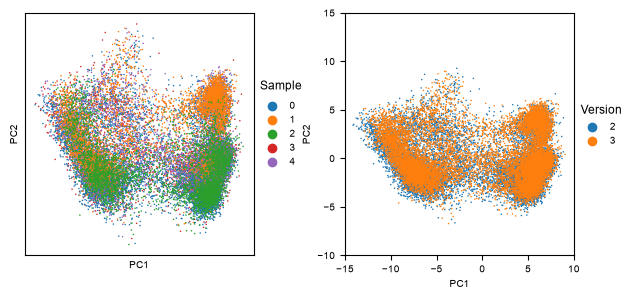

In [79]:
fig, ax = plt.subplots(1, 2, figsize=(18/2.54, 8/2.54))

# temporarily replace X_pca with X_pca_harmony
# Save original PCA
dta.obsm['X_pca_original'] = dta.obsm['X_pca'].copy()
# Replace with harmony-corrected PCs
dta.obsm['X_pca'] = dta.obsm['X_pca_harmony'].copy()

# plot
sc.pl.pca(dta, color=['Sample'], dimensions=[(0, 1)],
          ax=ax[0], show=False, title='')
sc.pl.pca(dta, color=['version'], dimensions=[(0, 1)],
          ax=ax[1], show=False, title='')

ax[1].set_xlim(-15, 10)
ax[1].set_ylim(-10, 15)
ax[1].set_xticks(range(-15, 11, 5))
ax[1].set_yticks(range(-10, 16, 5))

ax[0].set_title('Sample', x=1.12, y=0.65)
ax[1].set_title('Version', x=1.12, y=0.55)
fig.subplots_adjust(wspace=0.4)

plt.savefig(dir_out+'1.1_pc_scatter_tech_issues_solved.pdf', format='pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

# Restore original if needed
dta.obsm['X_pca'] = dta.obsm['X_pca_original'].copy()

In [83]:
sc.pp.neighbors(dta, use_rep='X_pca_harmony', n_pcs=50, n_neighbors=200)
sc.tl.umap(dta, n_components=2)

/Users/penghao.xia/miniforge3/envs/py_gene/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [84]:
sc.tl.leiden(dta, flavor="igraph", n_iterations=2, resolution=1)

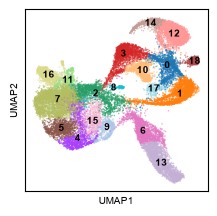

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(6/2.54, 6/2.54))

sc.pl.umap(dta, color=["leiden"], legend_loc='on data',
           ax=ax, show=False, title='', alpha=0.6)

plt.savefig(dir_out+'2_umap_scatter.pdf', format='pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

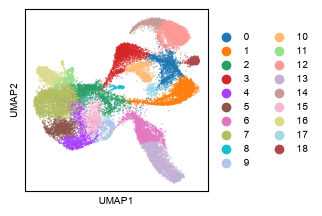

In [90]:
fig, ax = plt.subplots(1, 1, figsize=(6/2.54, 6/2.54))

sc.pl.umap(dta, color=["leiden"], ncols=2, 
           ax=ax, show=False, title='', alpha=0.6)
plt.savefig(dir_out+'2.1_umap_scatter_for_legend.pdf', format='pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

# Compare expression profiles

In [81]:
dta.raw = dta.copy()

In [82]:
sc.tl.rank_genes_groups(
    dta,
    groupby='leiden', # column in dta.obs
    method='wilcoxon', # recommended
    use_raw=True
)

KeyError: 'leiden'

In [21]:
# Extract results into a DataFrame
results = sc.get.rank_genes_groups_df(
    dta,
    group=None,        # None = all groups
    key='rank_genes_groups',
    pval_cutoff=0.05,  # filter by adjusted p-value
)
# rerank based on pvals_adj
results = results.sort_values('pvals_adj', ascending=True)[:500]
sig_genes = results['names'].unique().tolist()

In [ ]:
# # Extract top 3 genes per cluster
# top3_genes = sc.get.rank_genes_groups_df(
#     dta, 
#     group=None  # None = all groups
# )

# # Get top 3 per group
# top3 = (top3_genes
#         .groupby('group')
#         .head(1)  # top 3 per cluster (already ranked by score)
# )

# # Get ordered gene list (preserving cluster order)
# genes_to_plot = top3['names'].tolist()

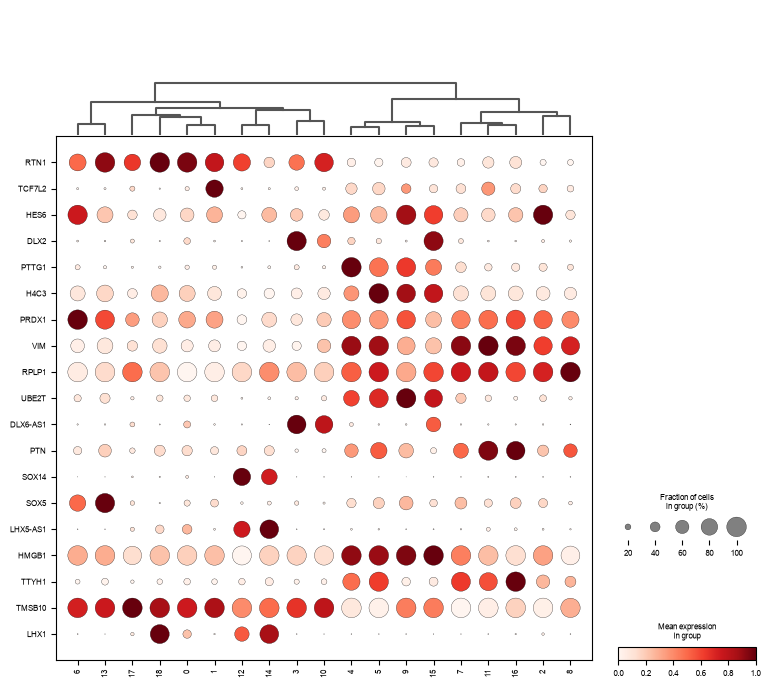

In [ ]:
# dp = sc.pl.dotplot(
#     dta,
#     var_names=genes_to_plot,
#     groupby='leiden',
#     dendrogram=True,
#     standard_scale="var",
#     swap_axes=True
# )


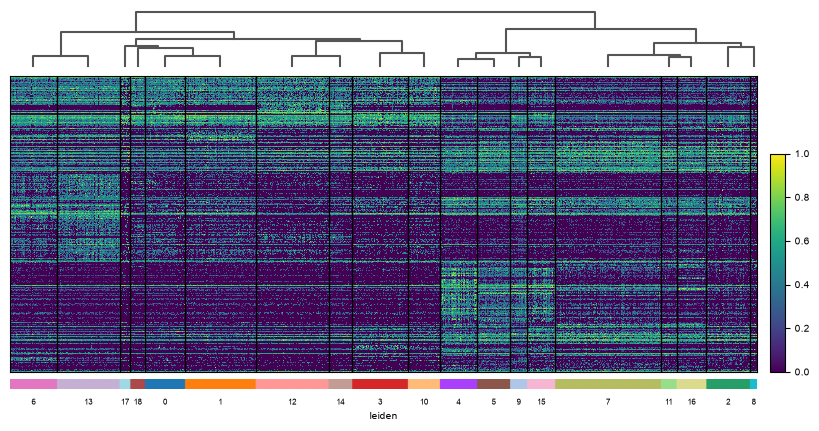

In [65]:
sc.pl.rank_genes_groups_heatmap(
    dta,
    groupby="leiden",
    # n_genes=5,
    standard_scale="var",
    # show_gene_labels=True,
    swap_axes=True,
    var_names=sig_genes, 
)

In [113]:
print(heatmap)

{'heatmap_ax': <Axes: >, 'groupby_ax': <Axes: xlabel='leiden'>, 'dendrogram_ax': <Axes: >, 'gene_groups_ax': <Axes: >}


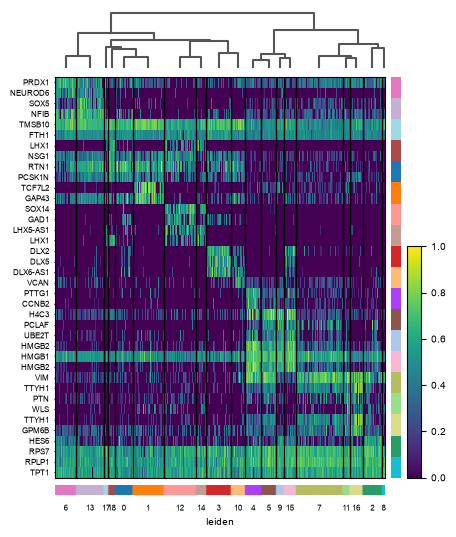

In [119]:
heatmap = sc.pl.rank_genes_groups_heatmap(dta, n_genes=2,
                                show_gene_labels=True,
                                swap_axes=True,
                                standard_scale="var",
                                figsize=(12/2.54, 16/2.54),
                                # return_fig=True,
                                show=False)

# heatmap['heatmap_ax'].savefig(dir_out+'3_heatmap.png', format='png', bbox_inches='tight', pad_inches=0.1)
# Save as PDF
plt.savefig(dir_out+'3_heatmap.pdf', format='pdf', bbox_inches='tight', pad_inches=0.1)